In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print("ML environment ready")

ML environment ready


In [2]:
from sklearn.datasets import load_diabetes
dataset = load_diabetes(as_frame=True)
df = dataset.frame
print(df.shape)
df.head()

(442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [2]:
from sklearn.datasets import load_diabetes
dataset = load_diabetes(as_frame=True)
df = dataset.frame
X = df.drop(columns=["target"])
y = df["target"]
print("X shape:", X.shape)
print("y shape:", y.shape)
print(X.head())


X shape: (442, 10)
y shape: (442,)
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  


In [3]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42
)
print(X_train.shape)
print(X_test.shape)



(353, 10)
(89, 10)


In [44]:
from sklearn.linear_model import LinearRegression
X1 = X[["bmi"]]
Xtr, Xte, ytr, yte = train_test_split(
X1, y, test_size=0.2, random_state=42
)
simple = LinearRegression()
simple.fit(Xtr, ytr)
pred = simple.predict(Xte)
print("Slope:", simple.coef_[0])
print("Intercept:", simple.intercept_)
print("First 5 predictions:", pred[:5])



Slope: 998.5776891375597
Intercept: 152.00335421448167
First 5 predictions: [145.80622687 188.85739048 147.95878505 203.92529774 131.8145987 ]


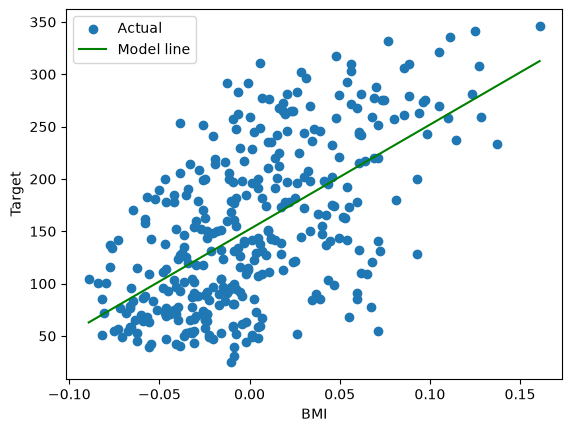

In [48]:
from sklearn.linear_model import LinearRegression
pred_train = simple.predict(Xtr)
order = np.argsort(Xtr["bmi"].values)
plt.scatter(Xtr["bmi"], ytr, label="Actual")
plt.plot(
Xtr["bmi"].values[order],
pred_train[order],
color="green", label="Model line"
)
plt.xlabel("BMI")
plt.ylabel("Target")
plt.legend()
plt.show()


In [62]:
multiple = LinearRegression()
multiple.fit(X_train, y_train)
pred_multi = multiple.predict(X_test)
print("Coefficients:", multiple.coef_)
print("Intercept:", multiple.intercept_)
print("First predictions:", pred_multi[:5])


Coefficients: [  37.90402135 -241.96436231  542.42875852  347.70384391 -931.48884588
  518.06227698  163.41998299  275.31790158  736.1988589    48.67065743]
Intercept: 151.34560453985995
First predictions: [139.5475584  179.51720835 134.03875572 291.41702925 123.78965872]


In [14]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
poly = make_pipeline(
PolynomialFeatures(degree=2, include_bias=False),
LinearRegression()
)
poly.fit(X_train[["bmi"]], y_train)
poly_pred = poly.predict(X_test[["bmi"]])
print(poly_pred[:5])


[144.31652431 187.37853935 146.40224431 203.1205058  130.93222915]


In [15]:
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test, pred_multi)
print("MSE:", mse)


MSE: 2900.1936284934804


In [17]:
x = np.array([1,2,3,4,5], dtype=float)
y_demo = np.array([2,4,6,8,10], dtype=float)
m, b = 0.0, 0.0
lr = 0.01
for epoch in range(1000):
    yhat = m*x + b
    dm = (-2/len(x))*np.sum(x*(y_demo-yhat))
    db = (-2/len(x))*np.sum(y_demo-yhat)
    m -= lr*dm
    b -= lr*db
    print(round(m, 2), round(b, 2))
print("Prediction at x=6:", round(m*6+b, 2))

0.44 0.12
0.78 0.21
1.03 0.28
1.23 0.33
1.38 0.37
1.49 0.4
1.58 0.42
1.65 0.44
1.7 0.45
1.74 0.46
1.77 0.47
1.79 0.47
1.81 0.48
1.82 0.48
1.83 0.48
1.84 0.48
1.85 0.48
1.85 0.48
1.86 0.48
1.86 0.48
1.86 0.48
1.86 0.48
1.86 0.47
1.87 0.47
1.87 0.47
1.87 0.47
1.87 0.47
1.87 0.47
1.87 0.47
1.87 0.46
1.87 0.46
1.87 0.46
1.87 0.46
1.87 0.46
1.87 0.46
1.87 0.46
1.87 0.45
1.87 0.45
1.88 0.45
1.88 0.45
1.88 0.45
1.88 0.45
1.88 0.44
1.88 0.44
1.88 0.44
1.88 0.44
1.88 0.44
1.88 0.44
1.88 0.44
1.88 0.43
1.88 0.43
1.88 0.43
1.88 0.43
1.88 0.43
1.88 0.43
1.88 0.43
1.88 0.42
1.88 0.42
1.88 0.42
1.88 0.42
1.88 0.42
1.88 0.42
1.88 0.42
1.89 0.41
1.89 0.41
1.89 0.41
1.89 0.41
1.89 0.41
1.89 0.41
1.89 0.41
1.89 0.4
1.89 0.4
1.89 0.4
1.89 0.4
1.89 0.4
1.89 0.4
1.89 0.4
1.89 0.4
1.89 0.39
1.89 0.39
1.89 0.39
1.89 0.39
1.89 0.39
1.89 0.39
1.89 0.39
1.89 0.38
1.89 0.38
1.89 0.38
1.89 0.38
1.89 0.38
1.9 0.38
1.9 0.38
1.9 0.38
1.9 0.37
1.9 0.37
1.9 0.37
1.9 0.37
1.9 0.37
1.9 0.37
1.9 0.37
1.9 0.37
1.9 0.36
1.

In [64]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score 

models = {
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1, max_iter=10000),
    "ElasticNet": ElasticNet(alpha=0.1, max_iter=10000)
}

for name, alg in models.items():
    pipe = make_pipeline(StandardScaler(), alg)
    pipe.fit(X_train, y_train)
    p = pipe.predict(X_test)
    print(name, "R2:", round(r2_score(y_test, p), 3))'

Ridge R2: 0.454
Lasso R2: 0.456
ElasticNet R2: 0.459


In [22]:
import statsmodels.api as sm
X_sm = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_sm).fit()
print(ols.summary())


                            OLS Regression Results                            
Dep. Variable:                 target   R-squared:                       0.528
Model:                            OLS   Adj. R-squared:                  0.514
Method:                 Least Squares   F-statistic:                     38.25
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           5.41e-50
Time:                        13:46:11   Log-Likelihood:                -1906.1
No. Observations:                 353   AIC:                             3834.
Df Residuals:                     342   BIC:                             3877.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        151.3456      2.902     52.155      0.0

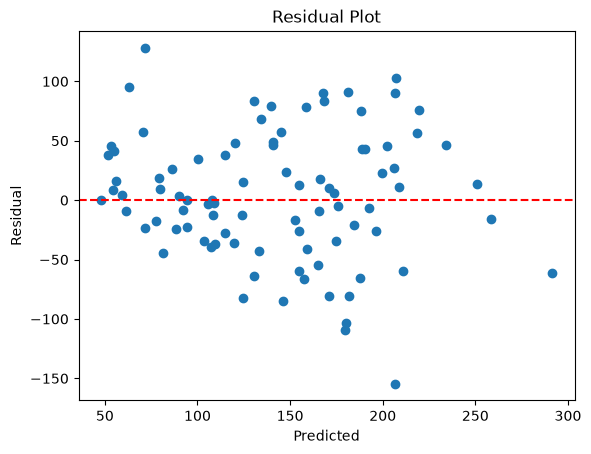

In [23]:
residuals = y_test - pred_multi
plt.scatter(pred_multi, residuals)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.show()

In [24]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
for degree in [1, 2, 5, 10]:
    model = make_pipeline(
    PolynomialFeatures(degree),
    LinearRegression()
    )
    model.fit(X_train[["bmi"]], y_train)
    tr = model.predict(X_train[["bmi"]])
    te = model.predict(X_test[["bmi"]])
    print(degree,
    mean_squared_error(y_train,tr),
    mean_squared_error(y_test,te))

1 3854.11265207582 4061.8259284949268
2 3849.3331334111795 4085.025480871632
5 3823.763813306945 4085.845566850978
10 3815.5854342370912 3979.509532458032


In [25]:
from sklearn.metrics import (
mean_absolute_error,
mean_squared_error,
r2_score
)
mae = mean_absolute_error(y_test, pred_multi)
mse = mean_squared_error(y_test, pred_multi)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, pred_multi)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 42.79409467959994
MSE: 2900.1936284934804
RMSE: 53.85344583676592
R2: 0.4526027629719196


In [26]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)
iris_df = iris.frame
Xc = iris_df.drop(columns=["target"])
yc = iris.target
print(Xc.head())
print(iris.target_names)


   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
['setosa' 'versicolor' 'virginica']


In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
Xtr, Xte, ytr, yte = train_test_split(
Xc, yc, test_size=0.2,
random_state=42, stratify=yc
)
log_model = make_pipeline(
StandardScaler(),
LogisticRegression(max_iter=2000)
)
log_model.fit(Xtr, ytr)
pred_log = log_model.predict(Xte)
print(pred_log[:10])


[0 2 1 1 0 1 0 0 2 1]


In [28]:
from sklearn.neighbors import KNeighborsClassifier
knn = make_pipeline(
StandardScaler(),
KNeighborsClassifier(n_neighbors=5)
)
knn.fit(Xtr, ytr)
pred_knn = knn.predict(Xte)
print(pred_knn[:10])

[0 2 1 1 0 1 0 0 2 1]


In [29]:
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()
nb.fit(Xtr, ytr)
pred_nb = nb.predict(Xte)
print(pred_nb[:10])

[0 2 1 1 0 1 0 0 2 1]


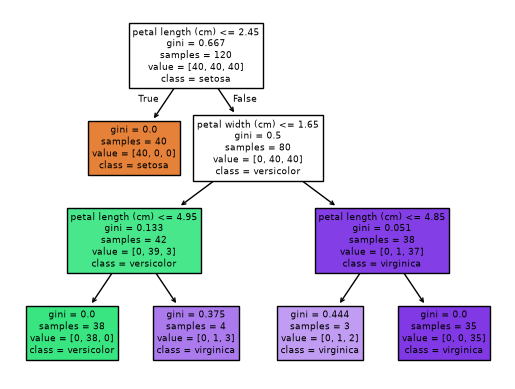

In [30]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
tree = DecisionTreeClassifier(
max_depth=3, random_state=42
)
tree.fit(Xtr, ytr)
pred_tree = tree.predict(Xte)
plot_tree(tree, feature_names=Xc.columns,
class_names=iris.target_names,
filled=True)
plt.show()


In [31]:
from sklearn.svm import SVC
svm = make_pipeline(
StandardScaler(),
SVC(kernel="rbf")
)
svm.fit(Xtr, ytr)
pred_svm = svm.predict(Xte)
print(pred_svm[:10])


[0 2 1 1 0 1 0 0 2 1]


In [34]:
from sklearn.metrics import accuracy_score
print("Classes:", iris.target_names)
print("Logistic accuracy:",
accuracy_score(yte, pred_log))
print("Tree accuracy:",
accuracy_score(yte, pred_tree))


Classes: ['setosa' 'versicolor' 'virginica']
Logistic accuracy: 0.9333333333333333
Tree accuracy: 0.9666666666666667


In [33]:
from sklearn.linear_model import LogisticRegression
weighted = LogisticRegression(
class_weight="balanced",
max_iter=2000
)
# Fit after applying the same
# preprocessing pipeline to X_train.
print("Balanced class weights enabled")

Balanced class weights enabled


In [50]:
import pandas as pd
from imblearn.over_sampling import SMOTE

threshold = y_train.quantile(0.75)
y_train_class = (y_train > threshold).astype(int)

smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_train_encoded, y_train_class)

print("Before:\n", y_train_class.value_counts())
print("\nAfter:\n", pd.Series(y_res).value_counts())

Before:
 target
0    266
1     87
Name: count, dtype: int64

After:
 target
0    266
1    266
Name: count, dtype: int64


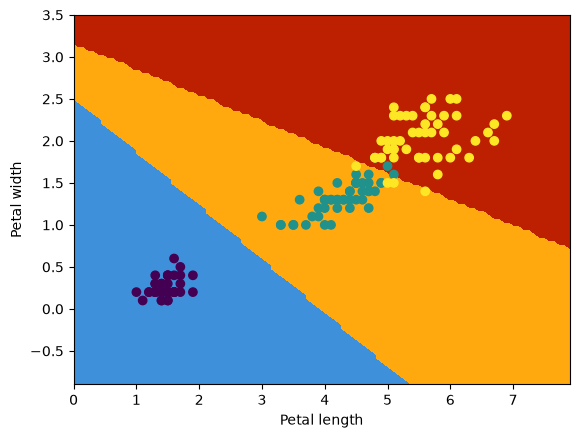

In [52]:
from sklearn.inspection import DecisionBoundaryDisplay
X2 = Xc[["petal length (cm)",
"petal width (cm)"]]
boundary_model = make_pipeline(
StandardScaler(),
LogisticRegression(max_iter=2000)
)
boundary_model.fit(X2, yc)
DecisionBoundaryDisplay.from_estimator(
boundary_model, X2,
response_method="predict",
plot_method="contourf"
)
plt.scatter(X2.iloc[:,0], X2.iloc[:,1], c=yc)
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.show()

In [60]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

iris = load_iris(as_frame=True)
_, X_test_iris, _, y_test_iris = train_test_split(
    iris.data, iris.target, test_size=0.2, random_state=42
)

pred_log = log_model.predict(X_test_iris)

print("Accuracy:", accuracy_score(y_test_iris, pred_log))
print("Precision:", precision_score(y_test_iris, pred_log, average="weighted"))
print("Recall:", recall_score(y_test_iris, pred_log, average="weighted"))
print("F1:", f1_score(y_test_iris, pred_log, average="weighted"))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1: 1.0


In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(
y_test_iris, pred_log,
display_labels=iris.target_names
)
plt.title("Iris Confusion Matrix")
plt.show()